# PinkMap - Notebook 2: Clean, Explore, and Baseline

**What this does (Weeks 5 and 6 of the class):**
1. Loads the spreadsheet(s) your collection notebook made
2. **Cleans** the data (removes broken or repeated rows)
3. Adds helpful new columns (**features**), like "how much slower than usual?" and "is it rush hour?"
4. **Splits** the data into a training part, a checking part, and a test part
5. Makes **charts** to find patterns
6. Builds a **baseline** guess so the real model later has something to beat

**How to use it:** click **Runtime -> Run all**. Run it again whenever you have collected more data.


## Step 1. Load the data
This looks for your `.csv` files in the PinkMap folder. If you got csv files from teammates, put them in the same folder, or set `UPLOAD_MORE = True` below.

PinkMap project: C:\Users\chris\PinkMap
Data folder: C:\Users\chris\PinkMap\data

Found 2 CSV file(s):
 - auto_collected.csv
 - route_data.csv

Loaded: auto_collected.csv
Rows and columns: (210, 9)
Columns: ['collected_at', 'route_id', 'origin', 'destination', 'distance_miles', 'traffic_seconds', 'typical_seconds', 'day_of_week', 'hour']

Loaded: route_data.csv
Rows and columns: (15, 9)
Columns: ['collected_at', 'route_id', 'origin', 'destination', 'distance_miles', 'traffic_seconds', 'typical_seconds', 'day_of_week', 'hour']

First five rows:


,collected_at,route_id,origin,destination,distance_miles,traffic_seconds,typical_seconds,day_of_week,hour
0,2026-10-07 14:41:38,1,Houston City College,Houston City College West Loop Campus,6.136,760.2,719.668,Wednesday,14
1,2026-10-07 14:41:38,2,Houston City College,Houston City College Northeast - Northline Campus,7.302,1157.9,1045.461,Wednesday,14
2,2026-10-07 14:41:38,3,Houston City College,Rice University,3.135,1087.1,1106.630,Wednesday,14
3,2026-10-07 14:41:38,4,Discovery Green,Hermann Park,4.807,804.0,763.814,Wednesday,14
4,2026-10-07 14:41:39,5,Discovery Green,University of Houston,3.308,845.4,791.255,Wednesday,14



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   collected_at     210 non-null    str    
 1   route_id         210 non-null    int64  
 2   origin           210 non-null    str    
 3   destination      210 non-null    str    
 4   distance_miles   210 non-null    float64
 5   traffic_seconds  210 non-null    float64
 6   typical_seconds  210 non-null    float64
 7   day_of_week      210 non-null    str    
 8   hour             210 non-null    int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 30.2 KB

Missing values by column:


,Missing values
collected_at,0
route_id,0
origin,0
destination,0
distance_miles,0
traffic_seconds,0
typical_seconds,0
day_of_week,0
hour,0



Duplicate rows: 0

Numeric summary:


,route_id,distance_miles,traffic_seconds,typical_seconds,hour
count,210.000000,210.000000,210.000000,210.000000,210.000000
mean,8.000000,8.402129,1079.579048,1028.195205,13.214286
std,4.330818,6.548951,463.434558,447.456560,6.169596
min,1.000000,2.871000,470.100000,480.679000,1.000000
25%,4.000000,4.807000,823.275000,788.030000,8.000000
50%,8.000000,6.280000,956.250000,897.383500,14.500000
75%,12.000000,9.762000,1144.725000,1103.504000,17.000000
max,15.000000,31.402000,2847.800000,2705.821000,23.000000



Original dataset shape: (210, 9)
Cleaned working dataset shape: (210, 9)

Numeric columns available for exploration:
['route_id', 'distance_miles', 'traffic_seconds', 'typical_seconds', 'hour']


C:\Users\chris\AppData\Local\Temp\ipykernel_31008\3743536742.py:102: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df_clean.select_dtypes(include=["object"]).columns:


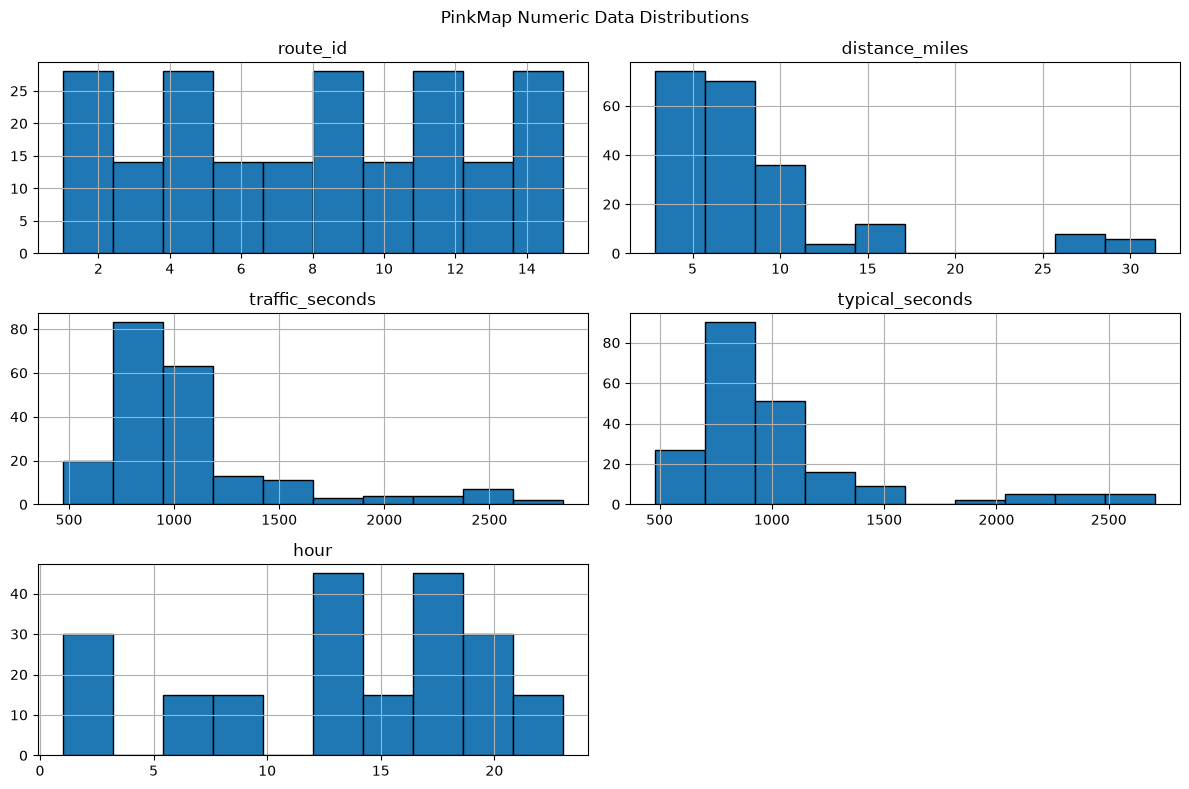


Cleaned dataset saved to:
C:\Users\chris\PinkMap\data\cleaned_data.csv

PinkMap data inspection and cleaning completed.
CSV files found: 2
   auto_collected.csv
   route_data.csv

Total rows loaded: 225


,collected_at,route_id,origin,destination,distance_miles,traffic_seconds,typical_seconds,day_of_week,hour
0,2026-10-07 14:41:38,1,Houston City College,Houston City College West Loop Campus,6.136,760.2,719.668,Wednesday,14
1,2026-10-07 14:41:38,2,Houston City College,Houston City College Northeast - Northline Campus,7.302,1157.9,1045.461,Wednesday,14
2,2026-10-07 14:41:38,3,Houston City College,Rice University,3.135,1087.1,1106.630,Wednesday,14
3,2026-10-07 14:41:38,4,Discovery Green,Hermann Park,4.807,804.0,763.814,Wednesday,14
4,2026-10-07 14:41:39,5,Discovery Green,University of Houston,3.308,845.4,791.255,Wednesday,14


In [1]:

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURATION: LOCAL WINDOWS STORAGE
# ============================================================

PROJECT_FOLDER = r"C:\Users\chris\PinkMap"
SAVE_FOLDER = os.path.join(PROJECT_FOLDER, "data")

# Create the data folder if it does not exist
os.makedirs(SAVE_FOLDER, exist_ok=True)

print("PinkMap project:", PROJECT_FOLDER)
print("Data folder:", SAVE_FOLDER)

# ============================================================
# 2. FIND CSV FILES
# ============================================================

UPLOAD_MORE = False  # Set True if you intend to add more CSV files

csv_files = sorted(glob.glob(os.path.join(SAVE_FOLDER, "*.csv")))

print(f"\nFound {len(csv_files)} CSV file(s):")

for file in csv_files:
    print(" -", os.path.basename(file))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found in {SAVE_FOLDER}. "
        "Check that your dataset is in the data folder."
    )

# ============================================================
# 3. LOAD CSV FILES
# ============================================================

datasets = {}

for file in csv_files:
    try:
        df = pd.read_csv(file)
        name = os.path.splitext(os.path.basename(file))[0]
        datasets[name] = df

        print(f"\nLoaded: {os.path.basename(file)}")
        print("Rows and columns:", df.shape)
        print("Columns:", df.columns.tolist())

    except Exception as error:
        print(f"Could not load {file}: {error}")

# ============================================================
# 4. SELECT THE MAIN DATASET
# ============================================================

# Prefer the project's existing auto_collected.csv when available.
if "auto_collected" in datasets:
    df = datasets["auto_collected"].copy()
else:
    first_dataset = next(iter(datasets))
    df = datasets[first_dataset].copy()
    print(f"\nUsing {first_dataset} as the main dataset.")

print("\nFirst five rows:")
display(df.head())

# ============================================================
# 5. INSPECT DATA TYPES AND QUALITY
# ============================================================

print("\nDataset information:")
df.info()

print("\nMissing values by column:")
display(df.isna().sum().to_frame("Missing values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumeric summary:")
display(df.describe(include=[np.number]))

# ============================================================
# 6. CREATE A CLEANED COPY
# ============================================================

# Preserve the original dataset.
df_clean = df.copy()

# Remove exact duplicate rows from the working copy.
df_clean = df_clean.drop_duplicates()

# Remove leading/trailing spaces from column names.
df_clean.columns = df_clean.columns.str.strip()

# Remove leading/trailing spaces from text values.
for column in df_clean.select_dtypes(include=["object"]).columns:
    df_clean[column] = df_clean[column].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

print("\nOriginal dataset shape:", df.shape)
print("Cleaned working dataset shape:", df_clean.shape)

# ============================================================
# 7. EXPLORE NUMERIC DATA
# ============================================================

numeric_columns = df_clean.select_dtypes(
    include=[np.number]
).columns.tolist()

if numeric_columns:
    print("\nNumeric columns available for exploration:")
    print(numeric_columns)

    df_clean[numeric_columns].hist(
        figsize=(12, 8),
        bins=10,
        edgecolor="black"
    )

    plt.suptitle("PinkMap Numeric Data Distributions")
    plt.tight_layout()
    plt.show()
else:
    print("\nNo numeric columns were found for plotting.")

# ============================================================
# 8. SAVE THE CLEANED DATASET AS A NEW FILE
# ============================================================

CLEAN_FILE = os.path.join(SAVE_FOLDER, "cleaned_data.csv")

df_clean.to_csv(CLEAN_FILE, index=False)

print("\nCleaned dataset saved to:")
print(CLEAN_FILE)

print("\nPinkMap data inspection and cleaning completed.")

if len(csv_files) == 0 or UPLOAD_MORE:
    print("Please choose your csv file(s) to upload.")
    from google.colab import files
    uploaded = files.upload()
    for name, content in uploaded.items():
        with open(os.path.join(SAVE_FOLDER, name), "wb") as f:
            f.write(content)
    csv_files = sorted(glob.glob(SAVE_FOLDER + "/*.csv"))

print("CSV files found:", len(csv_files))
for f in csv_files:
    print("  ", os.path.basename(f))

raw = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
print("\nTotal rows loaded:", len(raw))
raw.head()

## Step 2. Quality check (look before you clean)
How many values are missing? Are there repeated rows?

In [2]:
print("Missing values in each column:")
print(raw.isna().sum())

print("\nRepeated rows (same trip at the same time):",
      raw.duplicated(subset=["route_id", "collected_at"]).sum())

Missing values in each column:
collected_at       0
route_id           0
origin             0
destination        0
distance_miles     0
traffic_seconds    0
typical_seconds    0
day_of_week        0
hour               0
dtype: int64

Repeated rows (same trip at the same time): 0


## Step 3. Clean the data
We remove rows that cannot be trusted, and we write down how many we removed and why. Writing this down is part of the class requirement (data cleaning and quality assessment).

In [3]:
df = raw.copy()
start_rows = len(df)
log = []

# 1) Turn the time text into a real date and time
df["collected_at"] = pd.to_datetime(df["collected_at"], errors="coerce")

# 2) Make sure number columns are numbers
for col in ["distance_miles", "traffic_seconds", "typical_seconds"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 3) Remove rows missing something important
before = len(df)
df = df.dropna(subset=["collected_at", "distance_miles", "traffic_seconds", "typical_seconds"])
log.append(("Missing time, distance, traffic time, or typical time", before - len(df)))

# 4) Remove rows with impossible values
before = len(df)
df = df[(df["distance_miles"] > 0) & (df["traffic_seconds"] > 0) & (df["typical_seconds"] > 0)]
log.append(("Zero or negative values", before - len(df)))

# 5) Remove repeated rows
before = len(df)
df = df.drop_duplicates(subset=["route_id", "collected_at"])
log.append(("Repeated rows", before - len(df)))

df = df.sort_values("collected_at").reset_index(drop=True)

print("Rows before cleaning:", start_rows)
for reason, count in log:
    print(f"  removed {count:3d}  -  {reason}")
print("Rows after cleaning: ", len(df))

Rows before cleaning: 225
  removed   0  -  Missing time, distance, traffic time, or typical time
  removed   0  -  Zero or negative values
  removed   0  -  Repeated rows
Rows after cleaning:  225


## Step 4. Add helpful new columns (features)
These help the computer see patterns.

| New column | Meaning |
|---|---|
| `traffic_delay_seconds` | traffic time minus typical time (positive = slower than usual) |
| `traffic_status` | slower / faster / normal (more than 30 seconds off counts) |
| `hour`, `day_of_week`, `is_weekend` | when the trip was measured |
| `time_period` | morning, afternoon, evening, or night |
| `rush_hour` | 1 if it is 7-9 AM or 4-6 PM, otherwise 0 |
| `avg_speed_mph` | distance divided by travel time |

In [4]:
THRESHOLD_SECONDS = 30   # how far from "usual" counts as slower or faster

df["traffic_delay_seconds"] = df["traffic_seconds"] - df["typical_seconds"]

df["traffic_status"] = np.where(df["traffic_delay_seconds"] > THRESHOLD_SECONDS, "slower",
                        np.where(df["traffic_delay_seconds"] < -THRESHOLD_SECONDS, "faster", "normal"))

df["hour"] = df["collected_at"].dt.hour
df["day_of_week"] = df["collected_at"].dt.day_name()
df["is_weekend"] = (df["collected_at"].dt.dayofweek >= 5).astype(int)

df["time_period"] = np.where(df["hour"] < 12, "morning",
                     np.where(df["hour"] < 16, "afternoon",
                     np.where(df["hour"] < 20, "evening", "night")))

df["rush_hour"] = df["hour"].isin([7, 8, 16, 17]).astype(int)

df["avg_speed_mph"] = df["distance_miles"] / (df["traffic_seconds"] / 3600)

df.head()

,collected_at,route_id,origin,destination,distance_miles,traffic_seconds,typical_seconds,day_of_week,hour,traffic_delay_seconds,traffic_status,is_weekend,time_period,rush_hour,avg_speed_mph
0,2026-10-07 14:41:38,1,Houston City College,Houston City College West Loop Campus,6.136,760.2,719.668,Wednesday,14,40.532,slower,0,afternoon,0,29.057616
1,2026-10-07 14:41:38,2,Houston City College,Houston City College Northeast - Northline Campus,7.302,1157.9,1045.461,Wednesday,14,112.439,slower,0,afternoon,0,22.702479
2,2026-10-07 14:41:38,3,Houston City College,Rice University,3.135,1087.1,1106.630,Wednesday,14,-19.530,normal,0,afternoon,0,10.381750
3,2026-10-07 14:41:38,4,Discovery Green,Hermann Park,4.807,804.0,763.814,Wednesday,14,40.186,slower,0,afternoon,0,21.523881
4,2026-10-07 14:41:39,5,Discovery Green,University of Houston,3.308,845.4,791.255,Wednesday,14,54.145,slower,0,afternoon,0,14.086586


## Step 5. Split the data: train / validation / test
- **Train (70%)**: the computer learns from these rows
- **Validation (10%)**: used to check and tune while building
- **Test (20%)**: a final exam the model has never seen

We split by **time order** (oldest rows train, newest rows test). That way the model never "peeks" at the future.

In [5]:
n = len(df)
n_train = int(n * 0.70)
n_val = int(n * 0.10)

train = df.iloc[:n_train]
val = df.iloc[n_train:n_train + n_val]
test = df.iloc[n_train + n_val:]

print(f"Total {n} rows -> train {len(train)}, validation {len(val)}, test {len(test)}")
if n < 30:
    print("Tip: you have very little data. Collect more runs before trusting any results.")

Total 225 rows -> train 157, validation 22, test 46


## Step 6. Describe the data (Week 6)
Basic numbers, like the ones on your presentation slides, but now calculated from real data.

In [6]:
summary = {
    "Route observations (rows)": len(df),
    "Different trips (routes)": df["route_id"].nunique(),
    "Different collection hours": df["collected_at"].dt.strftime("%Y-%m-%d %H").nunique(),
    "Average distance (miles)": round(df["distance_miles"].mean(), 2),
    "Shortest / longest trip (miles)": f"{df['distance_miles'].min():.2f} / {df['distance_miles'].max():.2f}",
    "Average traffic travel time (minutes)": round(df["traffic_seconds"].mean() / 60, 2),
    "Average size of delay (seconds, ignoring + or -)": round(df["traffic_delay_seconds"].abs().mean(), 1),
    "Correlation: distance vs traffic time": round(df["distance_miles"].corr(df["traffic_seconds"]), 3),
}
for key, value in summary.items():
    print(f"{key}: {value}")

print("\nHow many rows were slower / faster / normal:")
print(df["traffic_status"].value_counts())

Route observations (rows): 225
Different trips (routes): 15
Different collection hours: 15
Average distance (miles): 8.41
Shortest / longest trip (miles): 2.87 / 31.40
Average traffic travel time (minutes): 17.77
Average size of delay (seconds, ignoring + or -): 76.1
Correlation: distance vs traffic time: 0.868

How many rows were slower / faster / normal:
traffic_status
slower    108
normal     76
faster     41
Name: count, dtype: int64


## Step 7. Charts: look for patterns

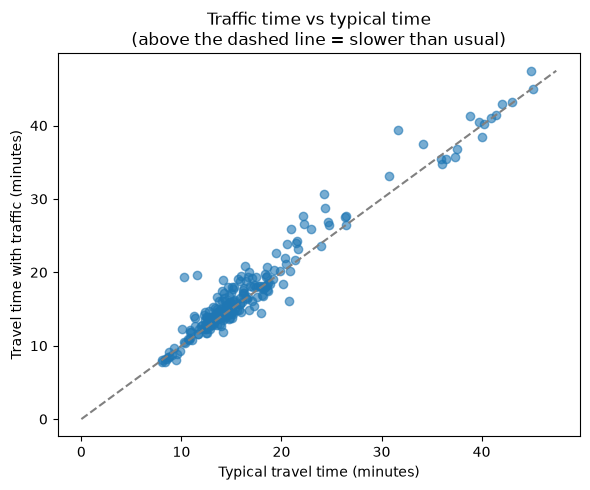

In [7]:
# Chart 1: traffic time vs typical time (dots above the line = slower than usual)
plt.figure(figsize=(6, 5))
plt.scatter(df["typical_seconds"] / 60, df["traffic_seconds"] / 60, alpha=0.6)
top = max(df["typical_seconds"].max(), df["traffic_seconds"].max()) / 60
plt.plot([0, top], [0, top], linestyle="--", color="gray")
plt.xlabel("Typical travel time (minutes)")
plt.ylabel("Travel time with traffic (minutes)")
plt.title("Traffic time vs typical time\n(above the dashed line = slower than usual)")
plt.tight_layout()
plt.show()

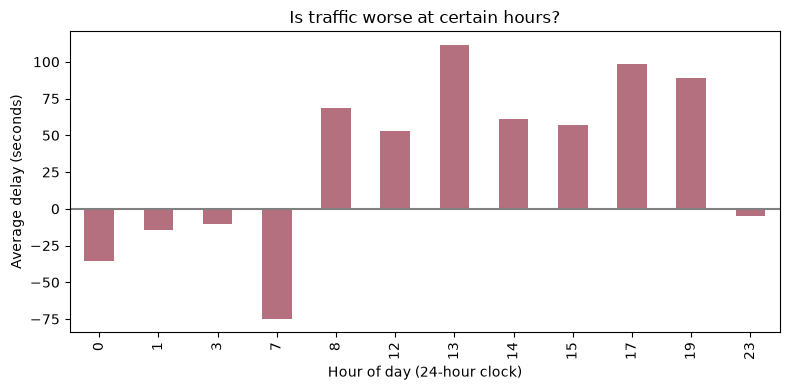

In [8]:
# Chart 2: average delay by hour of day
by_hour = df.groupby("hour")["traffic_delay_seconds"].mean()
plt.figure(figsize=(8, 4))
by_hour.plot(kind="bar", color="#b5707f")
plt.axhline(0, color="gray")
plt.xlabel("Hour of day (24-hour clock)")
plt.ylabel("Average delay (seconds)")
plt.title("Is traffic worse at certain hours?")
plt.tight_layout()
plt.show()

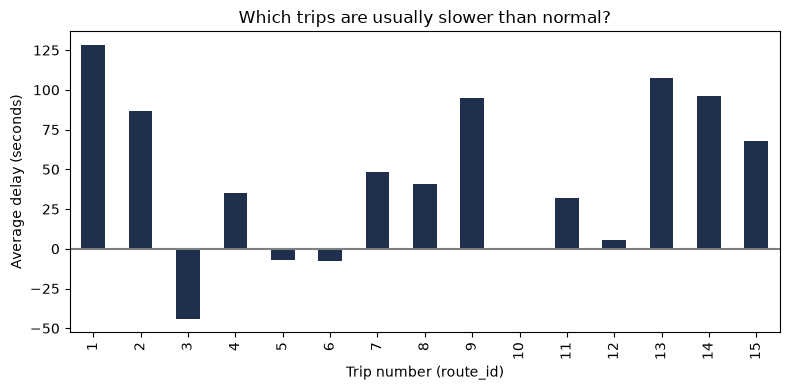

In [9]:
# Chart 3: average delay for each trip
by_route = df.groupby("route_id")["traffic_delay_seconds"].mean()
plt.figure(figsize=(8, 4))
by_route.plot(kind="bar", color="#1f2f4d")
plt.axhline(0, color="gray")
plt.xlabel("Trip number (route_id)")
plt.ylabel("Average delay (seconds)")
plt.title("Which trips are usually slower than normal?")
plt.tight_layout()
plt.show()

## Step 8. Baseline models
A **baseline** is a simple guess. Later, your real model must beat it.

- **Baseline A:** guess that traffic time = Mapbox's typical time
- **Baseline B:** a small straight-line model that uses distance and typical time

**MAE** = the average mistake in seconds. **RMSE** = like MAE, but big mistakes count extra. Smaller is better.

In [10]:
from sklearn.linear_model import LinearRegression

def errors(actual, guess):
    e = np.array(actual) - np.array(guess)
    return float(np.mean(np.abs(e))), float(np.sqrt(np.mean(e ** 2)))

target = "traffic_seconds"
inputs = ["distance_miles", "typical_seconds"]

if len(train) < 3 or len(test) < 1:
    print("Not enough data yet. Collect more runs and run this notebook again.")
else:
    # Baseline A
    a_mae, a_rmse = errors(test[target], test["typical_seconds"])

    # Baseline B
    lin = LinearRegression().fit(train[inputs], train[target])
    b_mae, b_rmse = errors(test[target], lin.predict(test[inputs]))

    results = pd.DataFrame({
        "Model": ["A: guess = typical time", "B: linear (distance + typical time)"],
        "Test MAE (sec)": [round(a_mae, 1), round(b_mae, 1)],
        "Test RMSE (sec)": [round(a_rmse, 1), round(b_rmse, 1)],
    })
    print(f"Test rows used: {len(test)}")
    display(results)

Test rows used: 46


,Model,Test MAE (sec),Test RMSE (sec)
0,A: guess = typical time,79.9,115.5
1,B: linear (distance + typical time),72.0,104.6


## Step 9. Save the cleaned files
These files go in a `processed` folder. The next notebook (the real model) will use them.

In [12]:

# Create the processed folder inside your local data folder
out = os.path.join(SAVE_FOLDER, "processed")
os.makedirs(out, exist_ok=True)

# Save the cleaned dataset and train/validation/test splits
df.to_csv(os.path.join(out, "clean_data.csv"), index=False)
train.to_csv(os.path.join(out, "train.csv"), index=False)
val.to_csv(os.path.join(out, "val.csv"), index=False)
test.to_csv(os.path.join(out, "test.csv"), index=False)

print("Saved clean_data.csv, train.csv, val.csv, and test.csv to:", out)

# Confirm that the files were created
print("\nFiles in processed folder:")
print(os.listdir(out))


Saved clean_data.csv, train.csv, val.csv, and test.csv to: C:\Users\chris\PinkMap\data\processed

Files in processed folder:
['clean_data.csv', 'test.csv', 'train.csv', 'val.csv']


## What to write in your notes for the professor
- **Where the data came from:** OpenStreetMap (places) and the Mapbox Directions API (traffic and typical travel times).
- **What we cleaned:** see the cleaning log in Step 3.
- **What we added:** delay, status, hour, day, rush hour, and speed (Step 4).
- **How we split:** by time, 70/10/20 (Step 5).
- **What we found:** see the charts and numbers in Steps 6-7.
- **Baseline results:** see the table in Step 8. With a small dataset, treat the numbers as a proof of concept, not a final result.
